# Projeto 2 — Alocação estável de alunos em projetos

**Teoria e Aplicação de Grafos — 2026/2, Turma A**

> **Integrantes:** preencher nomes e matrículas na célula de identificação abaixo.

Este notebook lê `entradaProj2.26TAG.txt`, valida os dados, constrói o grafo bipartido de candidaturas qualificadas, simula as duas direções de Gale–Shapley e procura um emparelhamento de cardinalidade máxima por caminhos aumentantes. Ao final, compara estabilidade, cobertura dos projetos e as classificações dos dois lados.

## Critérios adotados

- Um aluno só pode ser alocado a um projeto que indicou e para o qual atinge a nota mínima.
- A capacidade máxima de cada projeto é respeitada.
- Como a entrada não informa preferências próprias dos projetos, eles comparam alunos pela nota agregada: nota maior é estritamente melhor. **Notas iguais são empate real: o projeto não troca um aluno já aceito por outro de mesma nota.**
- A lista declarada pelo aluno é uma ordem estrita; códigos inexistentes são reportados e ignorados na execução.
- Gale–Shapley é executado nas duas direções. O resultado final estável prioriza a proposta dos projetos em caso de empate de cardinalidade.
- Caminhos aumentantes são usados separadamente para obter a cardinalidade máxima possível no grafo. Esse resultado serve como limite superior e diagnóstico; não é chamado de estável sem passar pelo teste de estabilidade.
- A exigência de pelo menos um aluno por projeto é verificada. Se os dados não permitirem cobrir todos, o notebook informa quais cotas mínimas ficaram descobertas.

**Estabilidade usada:** um par bloqueador precisa que o aluno prefira estritamente aquele projeto e que o projeto tenha vaga ou prefira estritamente aquele aluno. Empate de nota, por si só, não cria bloqueio.


In [1]:
# Identificação da equipe (preencher antes da entrega)
integrantes = [
    'Matheus Barbosa e Silva — 190113987',
    # 'PREENCHER: Nome completo — matrícula',
]
for integrante in integrantes:
    print(integrante)


Matheus Barbosa e Silva — 190113987


## 1. Bibliotecas e leitura dos dados

O código usa somente a biblioteca padrão do Python, além do `IPython.display` que acompanha o Jupyter para mostrar as visualizações SVG.


In [2]:
from collections import defaultdict, deque
from pathlib import Path
import html
import re

from IPython.display import SVG, display

INPUT_PATH = Path('entradaProj2.26TAG.txt')
if not INPUT_PATH.is_file():
    raise FileNotFoundError(
        'Não encontrei entradaProj2.26TAG.txt. Execute o notebook no diretório '
        'do arquivo de entrada.'
    )

project_pattern = re.compile(r'\((P\d+)\s*,\s*(\d+)\s*,\s*(\d+)\)')
student_pattern = re.compile(r'\((A\d+)\):\s*\(([^)]*)\)\s*\((\d+)\)')

projects = {}
students = {}
raw_preferences = {}
for line_number, raw_line in enumerate(
    INPUT_PATH.read_text(encoding='utf-8').splitlines(), start=1
):
    line = raw_line.strip()
    if not line or line.startswith('//'):
        continue
    project_match = project_pattern.fullmatch(line)
    if project_match:
        project_id, capacity, minimum_grade = project_match.groups()
        if project_id in projects:
            raise ValueError(f'Projeto duplicado na linha {line_number}: {project_id}')
        projects[project_id] = {
            'capacity': int(capacity),
            'minimum_grade': int(minimum_grade),
        }
        continue
    student_match = student_pattern.fullmatch(line)
    if student_match:
        student_id, preference_text, grade = student_match.groups()
        if student_id in students:
            raise ValueError(f'Aluno duplicado na linha {line_number}: {student_id}')
        raw_preferences[student_id] = tuple(re.findall(r'P\d+', preference_text))
        students[student_id] = {'grade': int(grade)}
        continue
    raise ValueError(f'Formato não reconhecido na linha {line_number}: {line}')

if not projects or not students:
    raise ValueError('A entrada precisa conter projetos e alunos.')

project_ids = sorted(projects, key=lambda code: int(code[1:]))
student_ids = sorted(students, key=lambda code: int(code[1:]))
known_projects = set(projects)


## 2. Validação e grafo de candidaturas qualificadas

Preferências repetidas são contadas uma única vez, mantendo sua primeira posição. Projetos citados que não existem na lista oficial são apresentados como inconsistências; não viram vértices nem propostas. Preferências para projetos existentes, mas cuja nota mínima não é atingida, não formam arestas admissíveis.


In [3]:
unknown_preferences = sorted(
    {
        project_id
        for preferences in raw_preferences.values()
        for project_id in preferences
        if project_id not in known_projects
    },
    key=lambda code: int(code[1:]),
)
duplicate_preferences = {
    student_id: tuple(
        project_id
        for project_id in dict.fromkeys(raw_preferences[student_id])
        if raw_preferences[student_id].count(project_id) > 1
    )
    for student_id in student_ids
}
duplicate_preferences = {
    student_id: values
    for student_id, values in duplicate_preferences.items()
    if values
}

student_preferences = {}
ineligible_preferences = []
for student_id in student_ids:
    valid_preferences = []
    seen = set()
    for project_id in raw_preferences[student_id]:
        if project_id not in known_projects or project_id in seen:
            continue
        seen.add(project_id)
        if students[student_id]['grade'] < projects[project_id]['minimum_grade']:
            ineligible_preferences.append((student_id, project_id))
            continue
        valid_preferences.append(project_id)
    student_preferences[student_id] = tuple(valid_preferences)

project_candidates = {project_id: [] for project_id in project_ids}
for student_id in student_ids:
    for project_id in student_preferences[student_id]:
        project_candidates[project_id].append(student_id)

project_preferences = {
    project_id: tuple(
        sorted(
            project_candidates[project_id],
            key=lambda student_id: (
                -students[student_id]['grade'],
                int(student_id[1:]),
            ),
        )
    )
    for project_id in project_ids
}

print(f'Projetos: {len(project_ids)} | alunos: {len(student_ids)}')
print(f'Vagas máximas somadas: {sum(projects[p]["capacity"] for p in project_ids)}')
print(f'Preferências inelegíveis (nota abaixo do mínimo): {len(ineligible_preferences)}')
print(f'Preferências duplicadas: {len(duplicate_preferences)} alunos')
print(f'Códigos de projeto inexistentes citados: {unknown_preferences or "nenhum"}')
print('Projetos sem candidato qualificado:', [
    project_id for project_id in project_ids if not project_candidates[project_id]
])


Projetos: 50 | alunos: 200
Vagas máximas somadas: 80
Preferências inelegíveis (nota abaixo do mínimo): 300
Preferências duplicadas: 11 alunos
Códigos de projeto inexistentes citados: nenhum
Projetos sem candidato qualificado: ['P11', 'P13', 'P19', 'P32', 'P33', 'P42', 'P46']


## 3. Gale–Shapley nas duas direções

Na proposta dos alunos, cada aluno segue sua lista e o projeto mantém até sua capacidade os alunos de maior nota. Um candidato só substitui alguém se tiver nota **estritamente maior** que a menor nota atualmente aceita; em empate, ficam os incumbentes. Na proposta dos projetos, cada projeto percorre os candidatos por nota decrescente, e o aluno retém sua opção mais alta.

Nos empates, a ordenação por código serve apenas para tornar a execução reprodutível quando um projeto ainda tem vagas; ela não define preferência entre alunos empatados nem permite substituição de um incumbente por outro empatado.


In [4]:
def student_rank(student_id, project_id):
    """Posição do projeto na lista original do aluno (1-based), ou infinito."""
    try:
        return raw_preferences[student_id].index(project_id) + 1
    except ValueError:
        return float('inf')


def gale_shapley_students_propose():
    held_by_project = {project_id: [] for project_id in project_ids}
    held_by_student = {}
    next_choice = {student_id: 0 for student_id in student_ids}
    free_students = deque(student_ids)

    while free_students:
        student_id = free_students.popleft()
        preferences = student_preferences[student_id]
        if next_choice[student_id] >= len(preferences):
            continue
        project_id = preferences[next_choice[student_id]]
        next_choice[student_id] += 1
        incumbents = held_by_project[project_id]
        capacity = projects[project_id]['capacity']

        if len(incumbents) < capacity:
            incumbents.append(student_id)
            held_by_student[student_id] = project_id
            continue

        lowest_grade = min(students[incumbent]['grade'] for incumbent in incumbents)
        if students[student_id]['grade'] > lowest_grade:
            # Em empate entre os incumbentes de menor nota, preserva-se a ordem de entrada.
            evicted = next(
                incumbent
                for incumbent in reversed(incumbents)
                if students[incumbent]['grade'] == lowest_grade
            )
            incumbents.remove(evicted)
            incumbents.append(student_id)
            held_by_student.pop(evicted)
            held_by_student[student_id] = project_id
            free_students.append(evicted)
        else:
            free_students.append(student_id) if next_choice[student_id] < len(preferences) else None

    return held_by_student


def gale_shapley_projects_propose():
    held_by_project = {project_id: [] for project_id in project_ids}
    held_by_student = {}
    next_candidate = {project_id: 0 for project_id in project_ids}
    free_projects = deque(project_ids)

    while free_projects:
        project_id = free_projects.popleft()
        candidates = project_preferences[project_id]
        capacity = projects[project_id]['capacity']
        while (
            len(held_by_project[project_id]) < capacity
            and next_candidate[project_id] < len(candidates)
        ):
            student_id = candidates[next_candidate[project_id]]
            next_candidate[project_id] += 1
            current_project = held_by_student.get(student_id)
            if current_project is not None and student_rank(
                student_id, current_project
            ) < student_rank(student_id, project_id):
                continue

            if current_project is not None:
                held_by_project[current_project].remove(student_id)
                if current_project not in free_projects:
                    free_projects.append(current_project)
            held_by_student[student_id] = project_id
            held_by_project[project_id].append(student_id)

        if (
            len(held_by_project[project_id]) < capacity
            and next_candidate[project_id] < len(candidates)
            and project_id not in free_projects
        ):
            free_projects.append(project_id)

    return held_by_student


def blocking_pairs(matching):
    blocks = []
    for student_id in student_ids:
        current_project = matching.get(student_id)
        for project_id in student_preferences[student_id]:
            if project_id == current_project:
                continue
            if current_project is not None and student_rank(
                student_id, project_id
            ) > student_rank(student_id, current_project):
                continue
            occupants = [
                other_id
                for other_id, assigned_project in matching.items()
                if assigned_project == project_id
            ]
            has_vacancy = len(occupants) < projects[project_id]['capacity']
            strictly_prefers = (
                bool(occupants)
                and students[student_id]['grade']
                > min(students[other_id]['grade'] for other_id in occupants)
            )
            if has_vacancy or strictly_prefers:
                blocks.append((student_id, project_id))
    return blocks


student_proposing = gale_shapley_students_propose()
project_proposing = gale_shapley_projects_propose()

for label, matching in (
    ('Proposta dos alunos', student_proposing),
    ('Proposta dos projetos', project_proposing),
):
    print(
        f'{label}: {len(matching)} alunos alocados; '
        f'{len(blocking_pairs(matching))} pares bloqueadores.'
    )


Proposta dos alunos: 57 alunos alocados; 0 pares bloqueadores.
Proposta dos projetos: 57 alunos alocados; 0 pares bloqueadores.


## 4. Caminhos alternados — dez iterações determinísticas

Para estimar o máximo de alunos que podem ser alocados no grafo, cada projeto é tratado como um vértice com capacidade (não como vagas criadas artificialmente na saída). A busca tenta aumentar a alocação por caminhos alternados: quando um projeto está cheio, procura-se realocar um aluno já alocado antes de desistir. A ordem de alunos e preferências é fixa, sem aleatoriedade.

Cada iteração percorre, em ordem, os alunos ainda não alocados e registra os aumentos obtidos. Após dez iterações, a cardinalidade alcançada é comparada com as soluções estáveis. O emparelhamento dessa etapa maximiza cardinalidade no grafo, mas pode não ser estável; a estabilidade é calculada separadamente.


In [5]:
def try_augment(
    student_id,
    matching,
    assigned_by_project,
    seen_students,
    seen_projects,
    explored_edges,
    rejected_edges,
):
    if student_id in seen_students:
        return False
    seen_students.add(student_id)

    for project_id in student_preferences[student_id]:
        if project_id in seen_projects:
            continue
        seen_projects.add(project_id)
        explored_edges.append((student_id, project_id))
        occupants = assigned_by_project[project_id]
        if len(occupants) < projects[project_id]['capacity']:
            occupants.append(student_id)
            matching[student_id] = project_id
            return True

        for incumbent in sorted(occupants, key=lambda code: int(code[1:])):
            if try_augment(
                incumbent,
                matching,
                assigned_by_project,
                seen_students,
                seen_projects,
                explored_edges,
                rejected_edges,
            ):
                occupants.remove(incumbent)
                occupants.append(student_id)
                matching[student_id] = project_id
                return True
        rejected_edges.append((student_id, project_id))
    return False


maximum_matching = {}
assigned_by_project = {project_id: [] for project_id in project_ids}
iteration_states = []
for iteration in range(1, 11):
    size_before = len(maximum_matching)
    active_edges = set()
    rejected_edges = set()
    for student_id in student_ids:
        if student_id in maximum_matching:
            continue
        explored = []
        rejected = []
        before = dict(maximum_matching)
        augmented = try_augment(
            student_id,
            maximum_matching,
            assigned_by_project,
            set(),
            set(),
            explored,
            rejected,
        )
        rejected_edges.update(rejected)
        if augmented:
            for changed_student in set(before) | set(maximum_matching):
                old_project = before.get(changed_student)
                new_project = maximum_matching.get(changed_student)
                if old_project != new_project:
                    if old_project is not None:
                        active_edges.add((changed_student, old_project))
                    if new_project is not None:
                        active_edges.add((changed_student, new_project))
    iteration_states.append(
        {
            'matching': dict(maximum_matching),
            'active': active_edges,
            'rejected': rejected_edges,
        }
    )
    print(
        f'Iteração {iteration:02}: {len(maximum_matching)} alunos '
        f'(aumento de {len(maximum_matching) - size_before}).'
    )

print(f'Cardinalidade máxima encontrada: {len(maximum_matching)}')


Iteração 01: 63 alunos (aumento de 63).
Iteração 02: 63 alunos (aumento de 0).
Iteração 03: 63 alunos (aumento de 0).
Iteração 04: 63 alunos (aumento de 0).
Iteração 05: 63 alunos (aumento de 0).
Iteração 06: 63 alunos (aumento de 0).
Iteração 07: 63 alunos (aumento de 0).
Iteração 08: 63 alunos (aumento de 0).
Iteração 09: 63 alunos (aumento de 0).
Iteração 10: 63 alunos (aumento de 0).
Cardinalidade máxima encontrada: 63


## 5. Visualização do grafo e da evolução

Cada figura mostra o grafo bipartido de candidaturas qualificadas: projetos à esquerda e alunos à direita. As arestas de alocação temporária são azuis, as alterações do caminho aumentante da iteração são verdes e as rejeições daquela iteração são vermelhas. As demais candidaturas aparecem em cinza. A figura é SVG e pode ser ampliada.


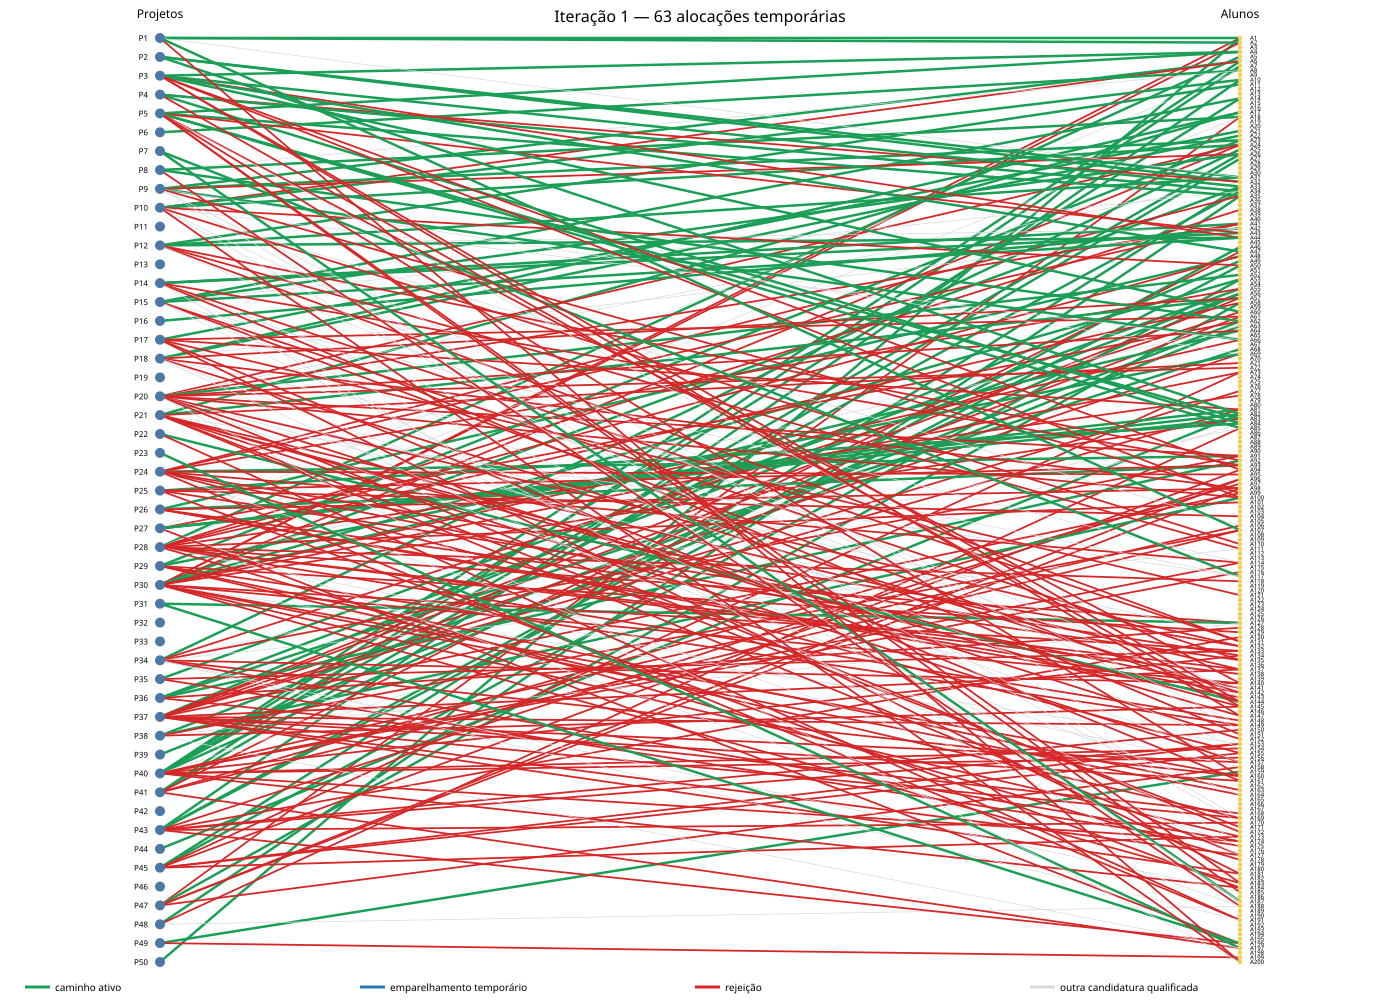

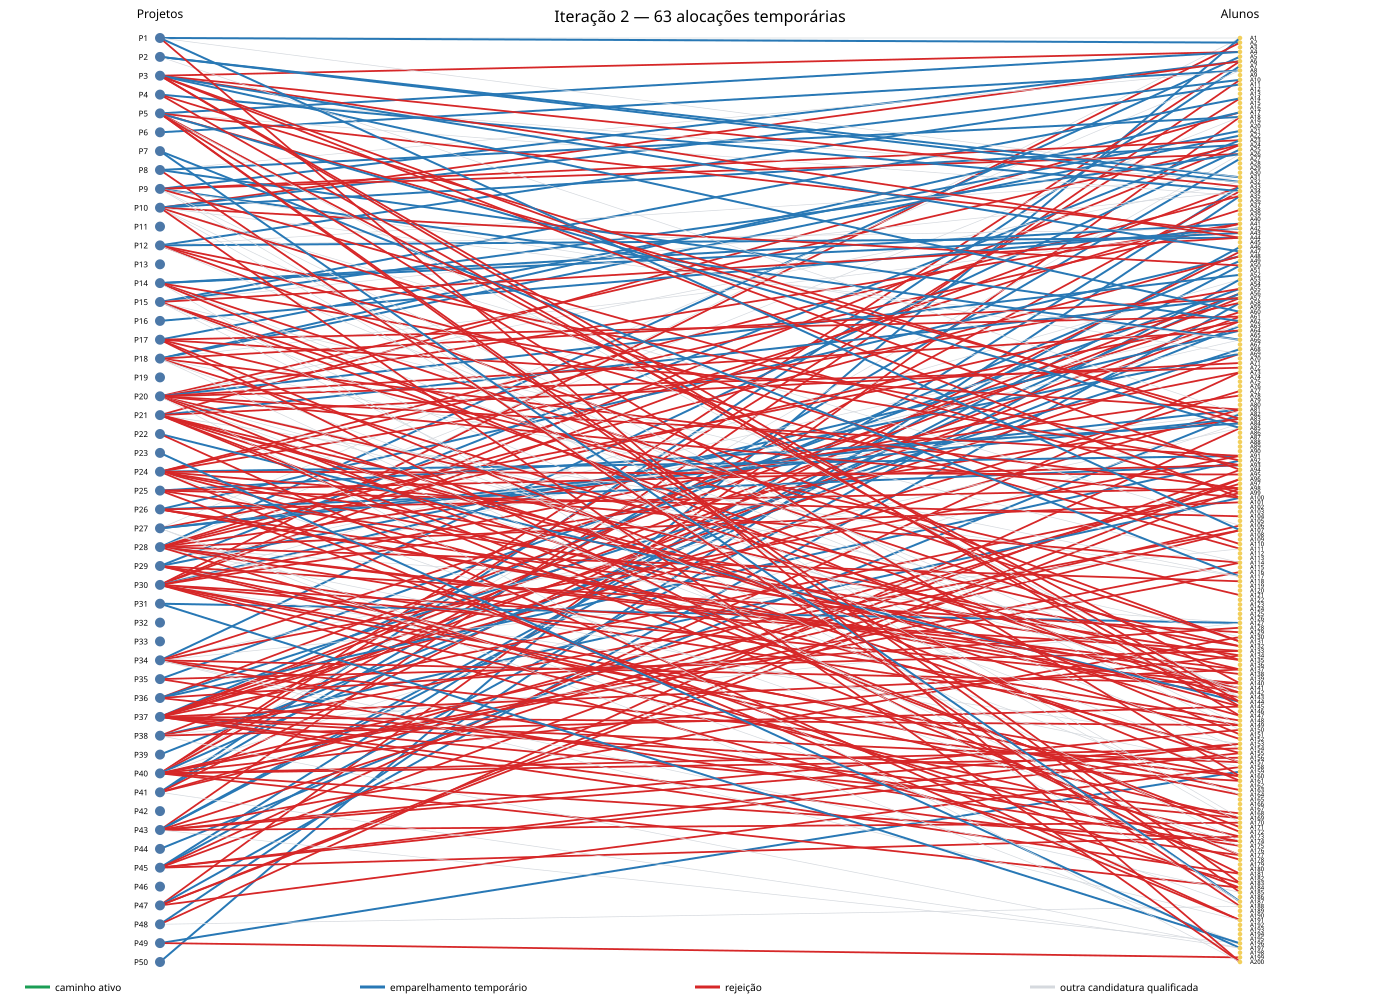

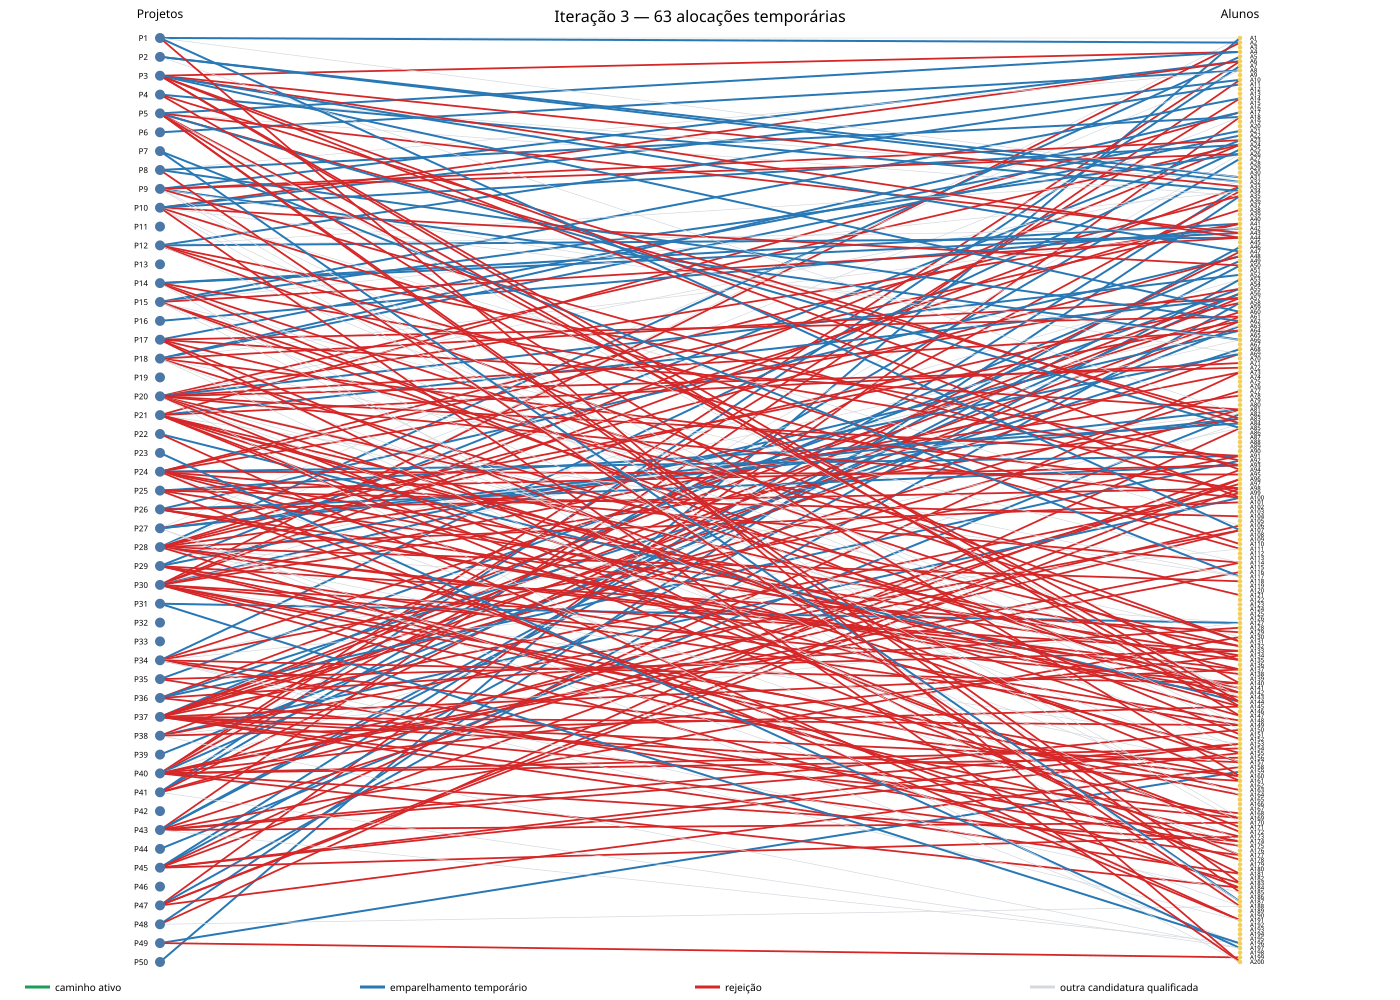

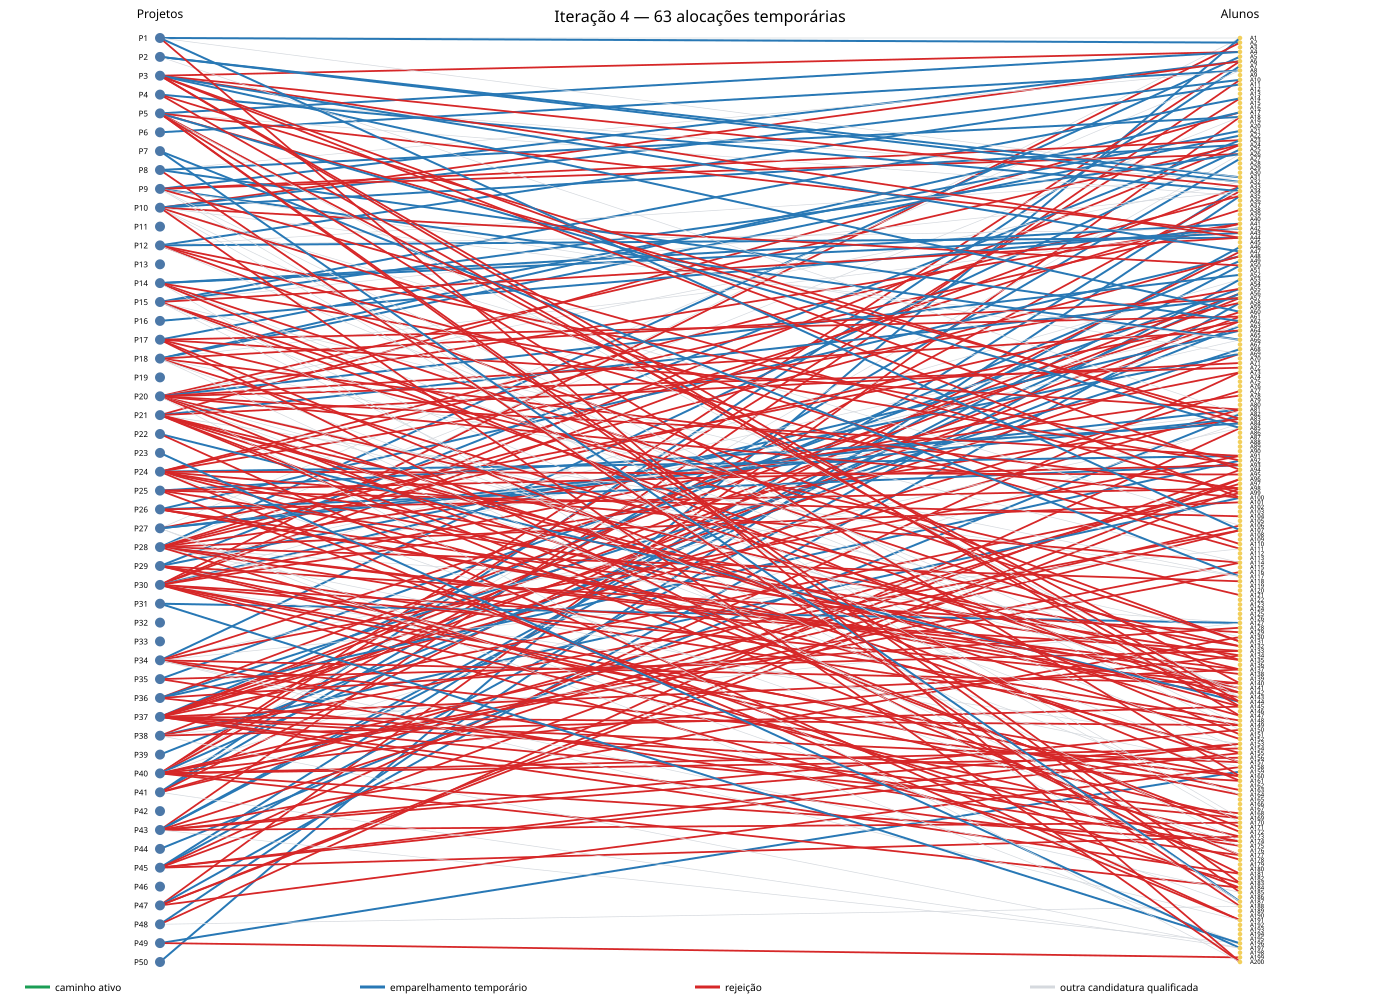

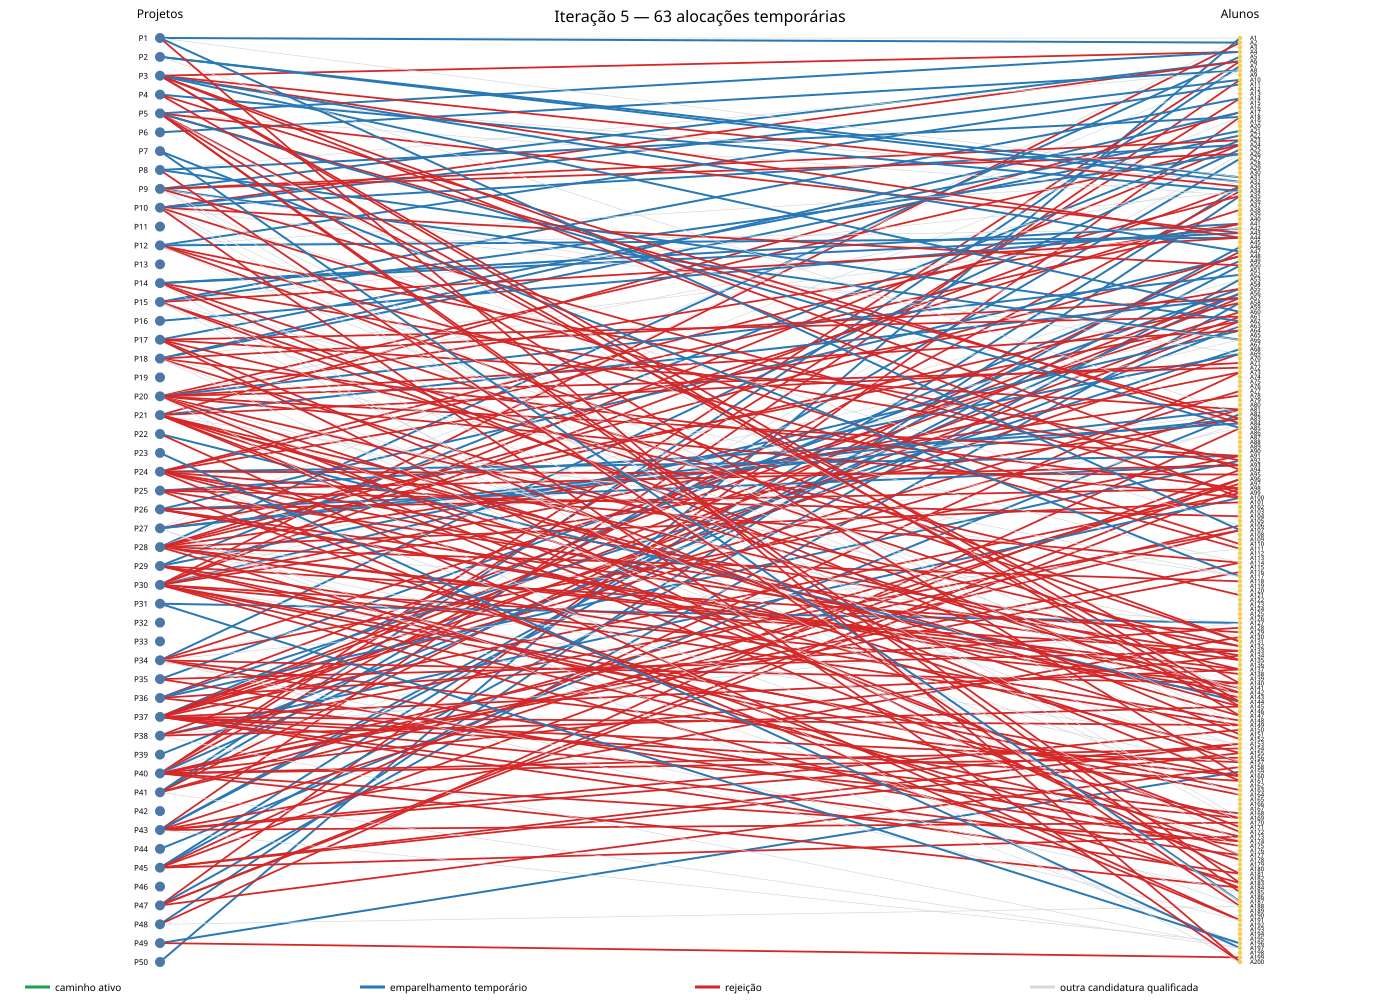

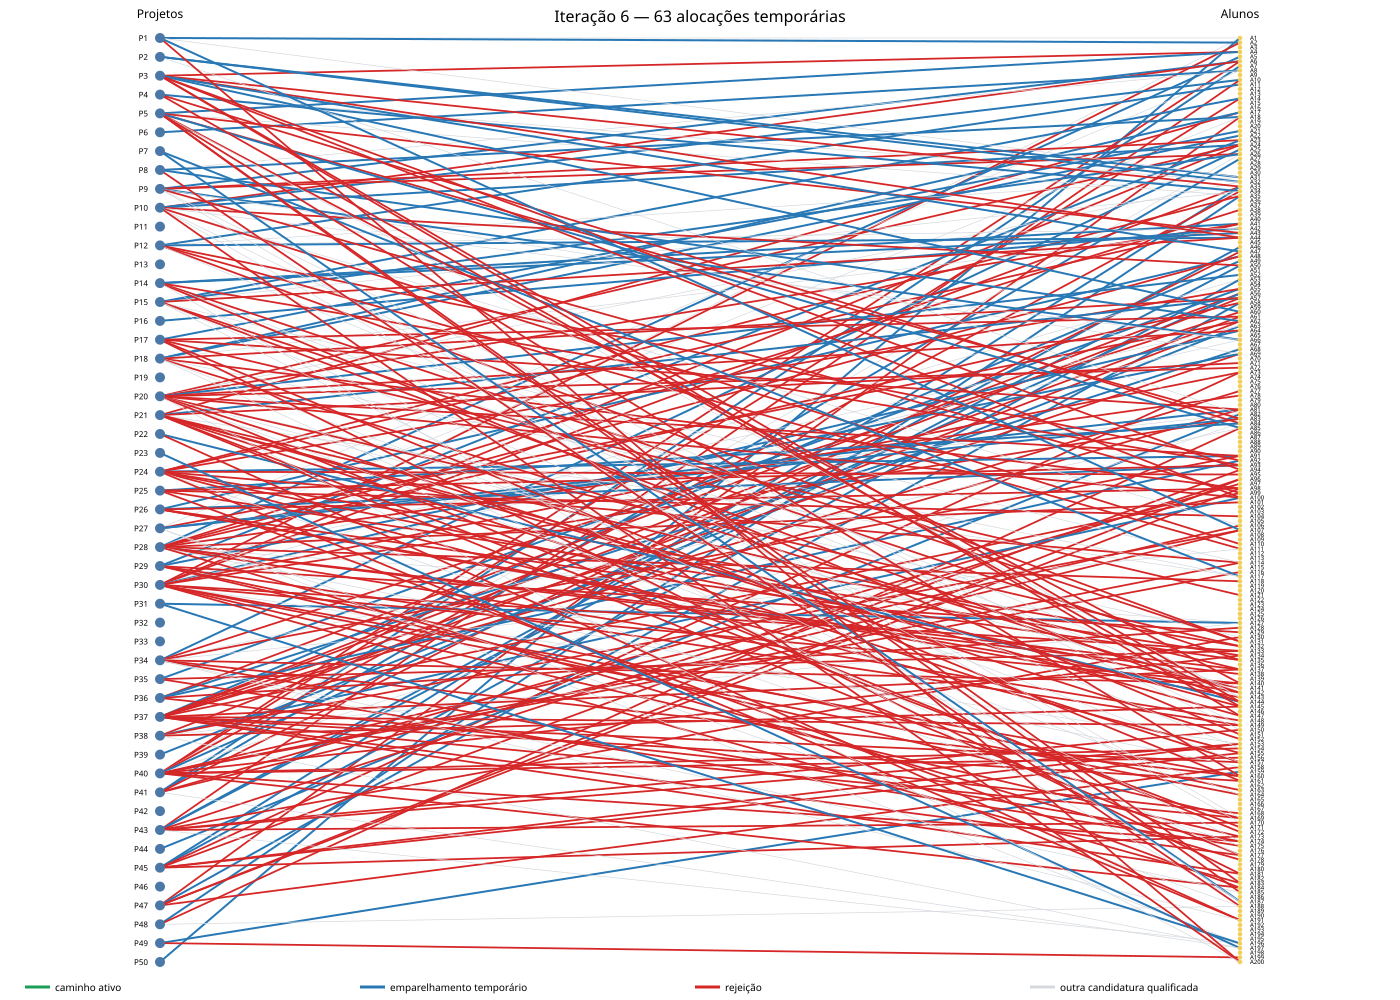

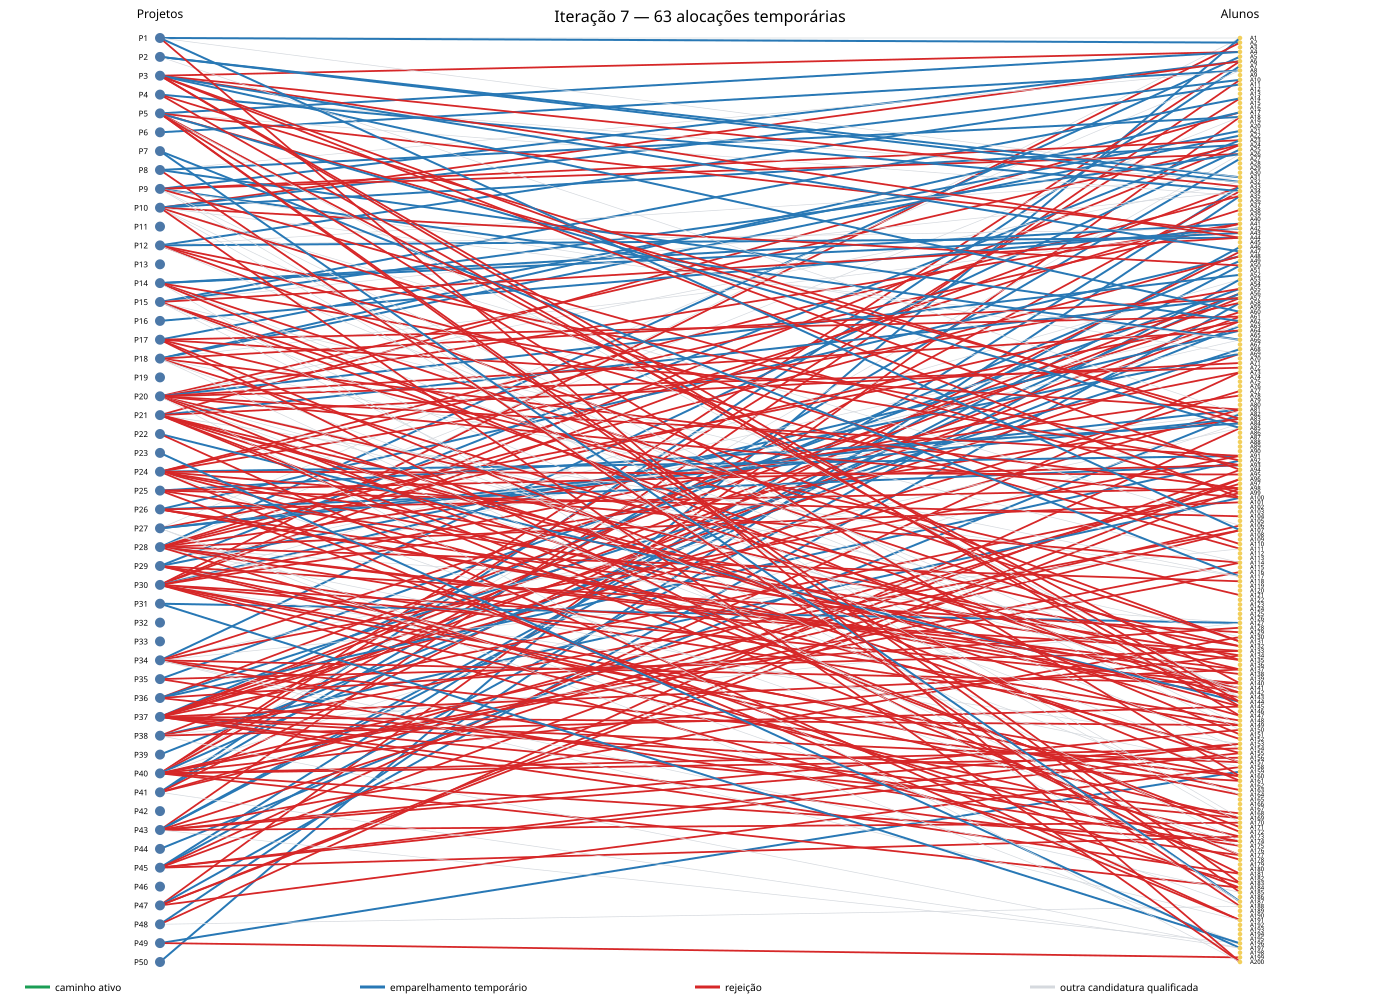

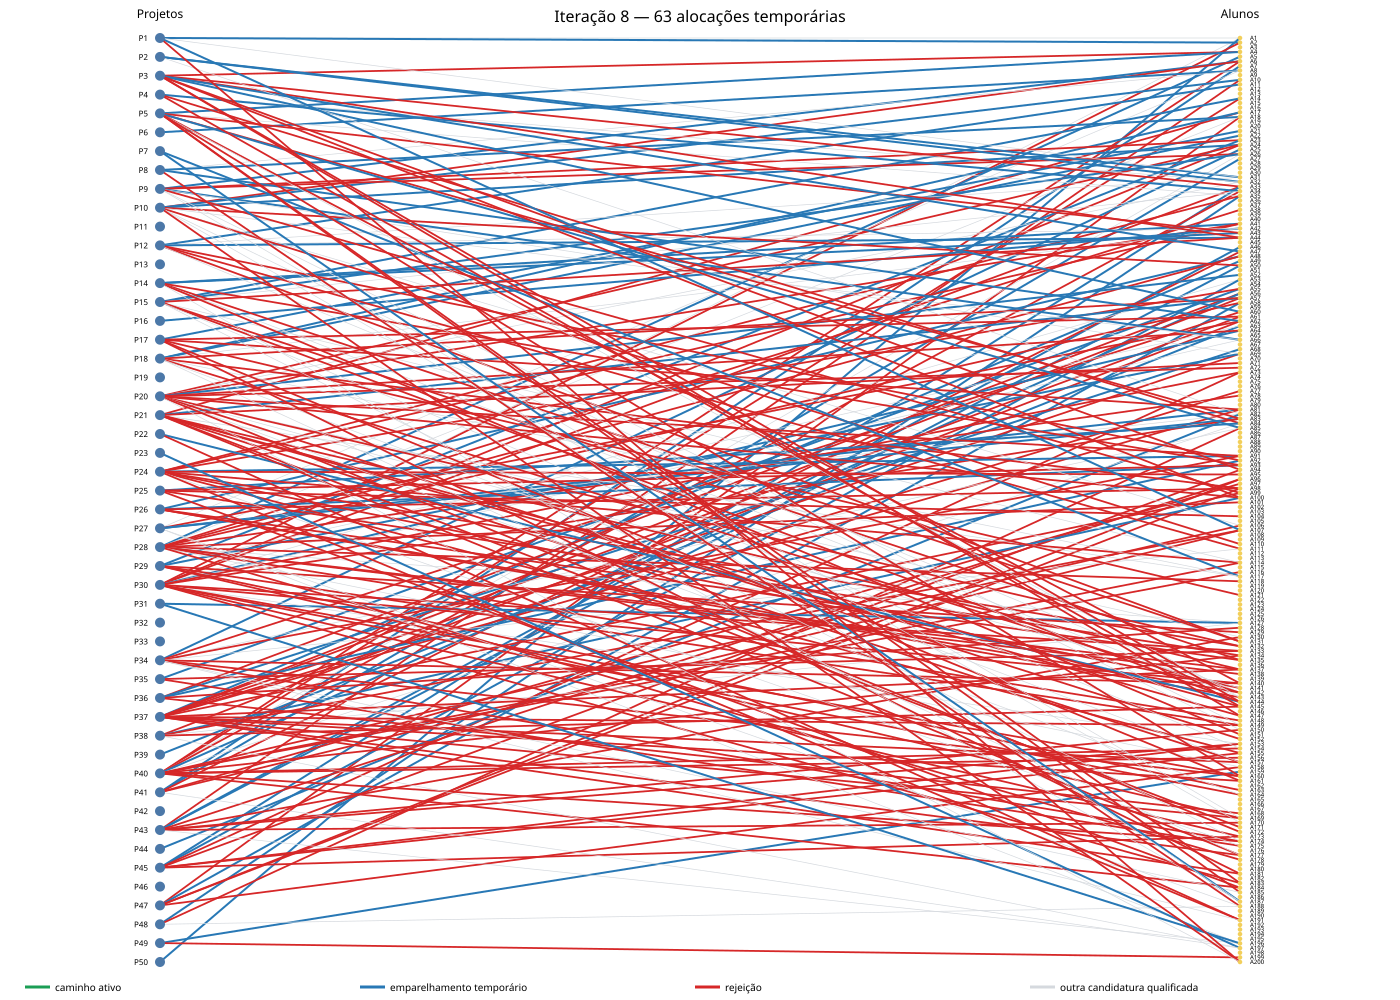

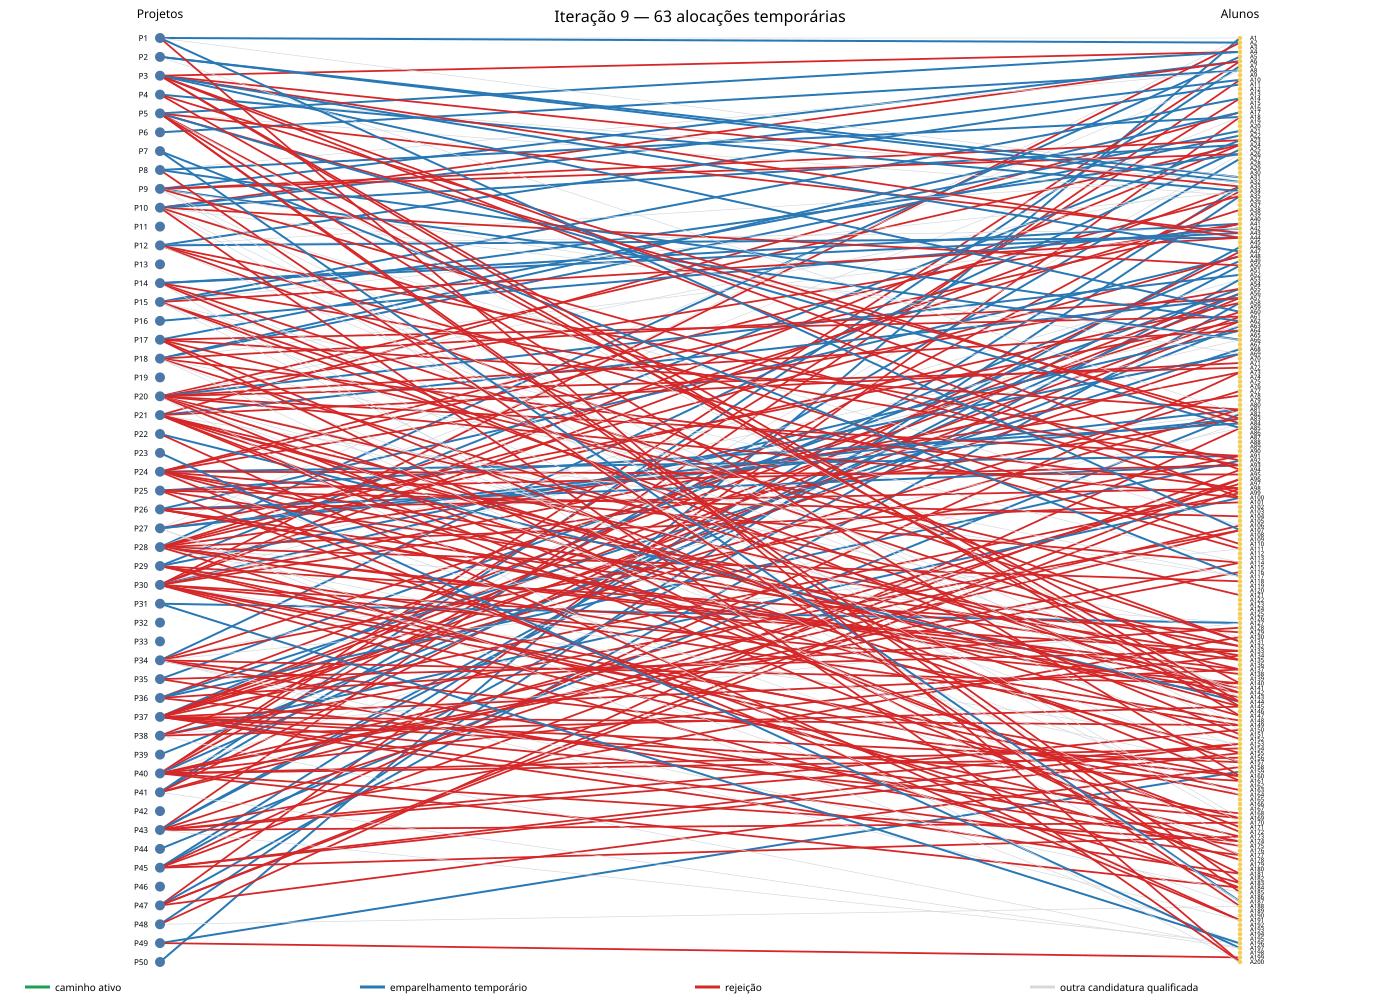

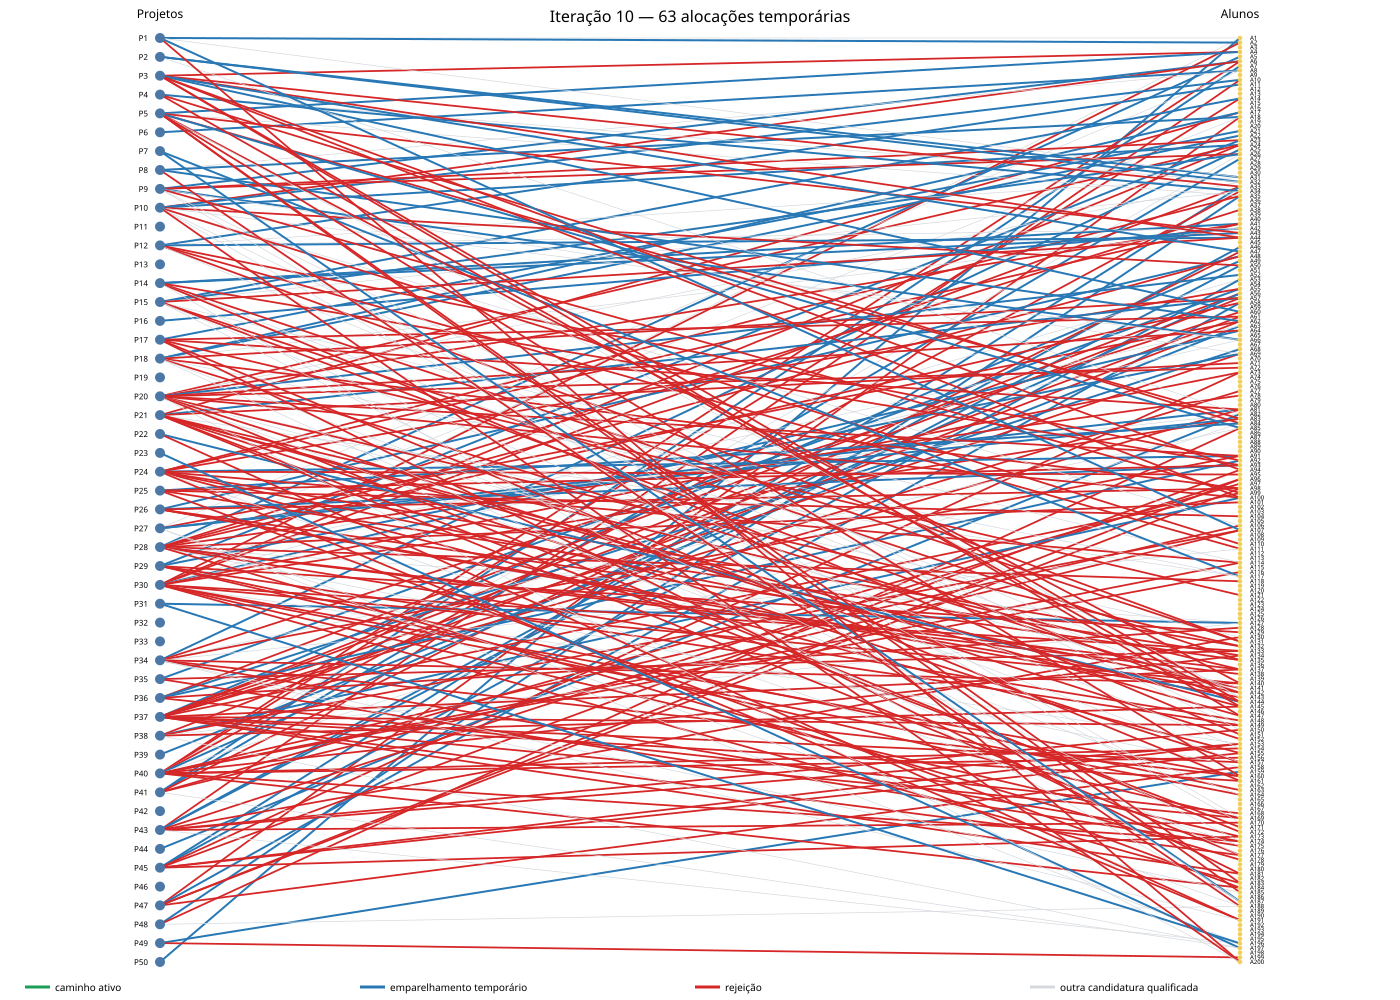

In [6]:
def matching_svg(state, iteration):
    width, height = 1400, 1000
    top, bottom = 38, height - 38
    project_y = {
        project_id: top + index * (bottom - top) / max(1, len(project_ids) - 1)
        for index, project_id in enumerate(project_ids)
    }
    student_y = {
        student_id: top + index * (bottom - top) / max(1, len(student_ids) - 1)
        for index, student_id in enumerate(student_ids)
    }
    matched_edges = {
        (student_id, project_id)
        for student_id, project_id in state['matching'].items()
    }
    elements = [
        f'<svg xmlns="http://www.w3.org/2000/svg" width="{width}" '
        f'height="{height}" viewBox="0 0 {width} {height}">',
        '<rect width="100%" height="100%" fill="white"/>',
        f'<text x="{width / 2}" y="22" text-anchor="middle" '
        f'font-family="sans-serif" font-size="16">Iteração {iteration} — '
        f'{len(matched_edges)} alocações temporárias</text>',
        '<text x="160" y="18" text-anchor="middle" font-family="sans-serif" '
        'font-size="12">Projetos</text>',
        '<text x="1240" y="18" text-anchor="middle" font-family="sans-serif" '
        'font-size="12">Alunos</text>',
    ]
    for student_id in student_ids:
        for project_id in student_preferences[student_id]:
            edge = (student_id, project_id)
            if edge in state['active']:
                color, stroke = '#1b9e55', '2.5'
            elif edge in matched_edges:
                color, stroke = '#2878b5', '2'
            elif edge in state['rejected']:
                color, stroke = '#d62728', '1.8'
            else:
                color, stroke = '#d5d9de', '0.7'
            elements.append(
                f'<line x1="160" y1="{project_y[project_id]:.1f}" '
                f'x2="1240" y2="{student_y[student_id]:.1f}" '
                f'stroke="{color}" stroke-width="{stroke}"/>'
            )
    for project_id in project_ids:
        y = project_y[project_id]
        label = html.escape(project_id)
        elements.append(
            f'<circle cx="160" cy="{y:.1f}" r="5" fill="#4c78a8"/>'
            f'<text x="148" y="{y + 3:.1f}" text-anchor="end" '
            f'font-family="sans-serif" font-size="8">{label}</text>'
        )
    for student_id in student_ids:
        y = student_y[student_id]
        elements.append(
            f'<circle cx="1240" cy="{y:.1f}" r="2.3" fill="#f2cf5b"/>'
            f'<text x="1250" y="{y + 2:.1f}" font-family="sans-serif" '
            f'font-size="6">{html.escape(student_id)}</text>'
        )
    legend = [
        ('#1b9e55', 'caminho ativo'),
        ('#2878b5', 'emparelhamento temporário'),
        ('#d62728', 'rejeição'),
        ('#d5d9de', 'outra candidatura qualificada'),
    ]
    x = 25
    for color, label in legend:
        elements.append(
            f'<line x1="{x}" y1="{height - 13}" x2="{x + 25}" '
            f'y2="{height - 13}" stroke="{color}" stroke-width="3"/>'
            f'<text x="{x + 30}" y="{height - 9}" font-family="sans-serif" '
            f'font-size="10">{html.escape(label)}</text>'
        )
        x += 335
    elements.append('</svg>')
    return ''.join(elements)


for iteration, state in enumerate(iteration_states, start=1):
    display(SVG(matching_svg(state, iteration)))


## 6. Comparação, cotas mínimas e solução final

O resultado estável escolhido é o de maior cardinalidade entre as duas direções de Gale–Shapley; em igualdade, usa-se a proposta dos projetos. Se sua cardinalidade atingir o máximo do grafo, ela é também máxima em cardinalidade entre todas as alocações. Se não atingir, o notebook sinaliza que as duas soluções estáveis comparadas não demonstram maximalidade global.


In [7]:
stable_candidates = [
    ('proposta dos projetos', project_proposing),
    ('proposta dos alunos', student_proposing),
]
stable_candidates.sort(
    key=lambda item: (
        -len(item[1]),
        0 if item[0] == 'proposta dos projetos' else 1,
    )
)
final_method, final_matching = stable_candidates[0]
final_blocks = blocking_pairs(final_matching)
uncovered_projects = [
    project_id
    for project_id in project_ids
    if not any(project == project_id for project in final_matching.values())
]
maximum_cardinality_verified = len(final_matching) == len(maximum_matching)

print(f'Método estável final: {final_method}')
print(f'Alunos alocados na solução estável: {len(final_matching)}')
print(f'Máximo de alunos no grafo: {len(maximum_matching)}')
print(f'Máxima cardinalidade estável demonstrada: {maximum_cardinality_verified}')
print(f'Pares bloqueadores na solução final: {len(final_blocks)}')
print(f'Projetos sem aluno na solução final: {uncovered_projects or "nenhum"}')
print(
    'Cota mínima de pelo menos um aluno por projeto atendida:',
    not uncovered_projects,
)

assert not final_blocks, 'A solução escolhida deve ser estável segundo o critério definido.'
assert all(
    sum(project == project_id for project in final_matching.values())
    <= projects[project_id]['capacity']
    for project_id in project_ids
), 'Uma capacidade máxima foi excedida.'
assert all(
    students[student_id]['grade'] >= projects[project_id]['minimum_grade']
    for student_id, project_id in final_matching.items()
), 'Uma alocação não atende à nota mínima.'


Método estável final: proposta dos projetos
Alunos alocados na solução estável: 57
Máximo de alunos no grafo: 63
Máxima cardinalidade estável demonstrada: False
Pares bloqueadores na solução final: 0
Projetos sem aluno na solução final: ['P11', 'P13', 'P19', 'P23', 'P31', 'P32', 'P33', 'P42', 'P44', 'P46', 'P48', 'P50']
Cota mínima de pelo menos um aluno por projeto atendida: False


## 7. Matriz final de emparelhamentos

Na lista de preferência do projeto, posições iguais indicam empate por nota. A posição do projeto na lista do aluno é a posição declarada originalmente; assim, a tabela evidencia a classificação obtida por cada lado. A segunda tabela permite comparar as direções de proposta.


In [8]:
def project_rank(project_id, student_id):
    grade = students[student_id]['grade']
    return 1 + sum(
        students[other_id]['grade'] > grade
        for other_id in project_candidates[project_id]
    )


def matching_table(matching, title):
    print(f'\n{title}')
    print(
        f'{"Aluno":<8} {"Projeto":<10} '
        f'{"Classificação do aluno na lista do projeto":<43} '
        f'{"Classificação do projeto na lista do aluno":<39}'
    )
    print('-' * 105)
    rows = sorted(
        matching.items(),
        key=lambda item: (
            int(item[1][1:]),
            int(item[0][1:]),
        ),
    )
    for student_id, project_id in rows:
        project_position = project_rank(project_id, student_id)
        student_position = student_rank(student_id, project_id)
        candidate_count = len(project_candidates[project_id])
        print(
            f'{student_id:<8} {project_id:<10} '
            f'{project_position}º (top {project_position} de {candidate_count})'
            f'{"":<16} '
            f'{student_position}º (preferência do aluno)'
        )


matching_table(final_matching, f'Solução final — {final_method}')
matching_table(
    student_proposing,
    'Comparação — proposta dos alunos',
)
matching_table(
    project_proposing,
    'Comparação — proposta dos projetos',
)



Solução final — proposta dos projetos
Aluno    Projeto    Classificação do aluno na lista do projeto  Classificação do projeto na lista do aluno
---------------------------------------------------------------------------------------------------------
A1       P1         1º (top 1 de 5)                 1º (preferência do aluno)
A2       P1         1º (top 1 de 5)                 1º (preferência do aluno)
A32      P2         1º (top 1 de 3)                 1º (preferência do aluno)
A82      P2         1º (top 1 de 3)                 1º (preferência do aluno)
A33      P3         1º (top 1 de 9)                 1º (preferência do aluno)
A60      P3         1º (top 1 de 9)                 1º (preferência do aluno)
A34      P4         1º (top 1 de 4)                 1º (preferência do aluno)
A35      P5         1º (top 1 de 10)                 1º (preferência do aluno)
A85      P5         1º (top 1 de 10)                 1º (preferência do aluno)
A8       P6         1º (top 1 de 1)         

## Conclusão e limitações

Os resultados e os diagnósticos acima devem ser preservados ao executar todas as células. Antes da entrega:

1. Substitua os campos de integrantes e matrículas.
2. Confira as inconsistências da entrada reportadas pelo notebook, em particular preferências para projetos inexistentes.
3. Registre se todos os projetos receberam pelo menos um aluno e se a solução estável atingiu o limite máximo do grafo.
4. Explique no mini-relatório que a regra de empate adotada é indiferença do projeto e manutenção do aluno incumbente, e que o teste de estabilidade considera preferência **estrita**.

Os caminhos alternados certificam a maior cardinalidade do emparelhamento no grafo de candidaturas, não a estabilidade dessa alocação. A comparação entre as duas variantes estáveis pode confirmar a cardinalidade máxima quando alcança esse limite; caso contrário, são necessários algoritmos adicionais para provar a existência ou inexistência de uma solução estável maior.
